# PCA
Aldo asked me to apply probabilistic PCA (PPCA) to hourly features as a means of dimensionality reduction. Not sure this is actually appropriate, I tried kernel PCA but dataset is way too big for that. 
Wants me to look at: how many components to explain the variance, whether patient groups cluster. Said something about passing data through autoencoders with different numbers of nodes (e.g. 1, 2, 3 etc)

In [1]:
import os
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import FactorAnalysis, PCA, KernelPCA
from sklearn.preprocessing import StandardScaler

# Sepsis patients only
## predicting mortality

In [2]:
df_path = "/home/jake/Documents/AI_Clinician/choc_data/combined_data/hourly/combined_hourly_features_phoenix_sepsis_prop_0.8.parquet"
df = pd.read_parquet(df_path)
df

,encounter_id,time,airway_type,breath_sequence,control_variable,expiratory_pressure,fio2,mean_airway_pressure,mode_of_ventilation,nitric_oxide,...,temperature,vis,age,mortality,sex,white,black,hispanic,asian,other
0,1165711196,2239-11-13 13:00:00,0.0,0.0,0.0,0.0,0.21,0.0,0.0,0.0,...,36.800,0.0,0.00,0.0,1.0,0,0,0,1,0
1,1165711196,2239-11-13 14:00:00,0.0,0.0,0.0,0.0,0.21,0.0,0.0,0.0,...,36.875,0.0,0.00,0.0,1.0,0,0,0,1,0
2,1165711196,2239-11-13 15:00:00,0.0,0.0,0.0,0.0,0.21,0.0,0.0,0.0,...,36.950,0.0,0.00,0.0,1.0,0,0,0,1,0
3,1165711196,2239-11-13 16:00:00,0.0,0.0,0.0,0.0,0.21,0.0,0.0,0.0,...,37.025,0.0,0.00,0.0,1.0,0,0,0,1,0
4,1165711196,2239-11-13 17:00:00,0.0,0.0,0.0,0.0,0.21,0.0,0.0,0.0,...,37.100,0.0,0.00,0.0,1.0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1818558,1189429156,2254-11-02 19:00:00,2.0,0.0,0.0,0.0,0.21,0.0,0.0,0.0,...,37.150,0.0,232.44,0.0,1.0,1,0,0,0,0
1818559,1189429156,2254-11-02 20:00:00,2.0,0.0,0.0,0.0,0.21,0.0,0.0,0.0,...,37.100,0.0,232.44,0.0,1.0,1,0,0,0,0
1818560,1189429156,2254-11-02 21:00:00,2.0,0.0,0.0,0.0,0.21,0.0,0.0,0.0,...,37.100,0.0,232.44,0.0,1.0,1,0,0,0,0
1818561,1189429156,2254-11-02 22:00:00,2.0,0.0,0.0,0.0,0.21,0.0,0.0,0.0,...,37.100,0.0,232.44,0.0,1.0,1,0,0,0,0


In [3]:
df.columns

Index(['encounter_id', 'time', 'airway_type', 'breath_sequence',
       'control_variable', 'expiratory_pressure', 'fio2',
       'mean_airway_pressure', 'mode_of_ventilation', 'nitric_oxide',
       'oxygen_flow', 'peep', 'pip', 'weight_kg', 'ecls_support_type',
       'on_ecls', 'cisatracurium', 'furosemide', 'hydralazine', 'labetalol',
       'nitroglycerin', 'nitroprusside', 'intake', 'alt', 'calcium',
       'chloride', 'creatinine', 'crp', 'hematocrit', 'hemoglobin',
       'neutrophil_count', 'neutrophil_percent', 'potassium', 'random_glucose',
       'sodium', 'white_blood_cell_count', 'fixed_pupils',
       'pupil_reaction_left_binary', 'pupil_reaction_right_binary',
       'chloral_hydrate', 'chlorothiazide', 'dexamethasone', 'dobutamine_dose',
       'furosemide_med', 'hydrocortisone', 'methylprednisolone', 'metolazone',
       'prednisolone', 'spironolactone', 'cisatracurium_med', 'clonidine_med',
       'dexmedetomidine_infusion', 'dexmedetomidine_med', 'fentanyl_infusion'

### only including physiological variables
### also excluding binary indicators (mostly pupil related) since PCA can overestimate their contributions

In [4]:
cols_to_keep = ['weight_kg', 'alt', 'calcium',
       'chloride', 'creatinine', 'crp', 'hematocrit', 'hemoglobin',
       'neutrophil_count', 'neutrophil_percent', 'potassium', 'random_glucose',
       'sodium', 'white_blood_cell_count',
       'blood_pressure_diastolic', 'blood_pressure_mean',
       'blood_pressure_systolic', 'capillary_refill', 'heart_rate',
       'oxygen_saturation', 'respiratory_rate', 'temperature', 'age',
       'sex', 'white', 'black', 'hispanic', 'asian', 'other']

In [80]:
# get the mortality encounters
mortality_encounters = df[df['mortality'] == 1]['encounter_id'].unique()
len(mortality_encounters)

220

In [82]:
df['mortality'].value_counts()

mortality
0.0    1656993
1.0     161570
Name: count, dtype: int64

In [83]:
# make all mortality encounters have mortality = 1
df.loc[df['encounter_id'].isin(mortality_encounters), 'mortality'] = 1
df['mortality'].value_counts()

mortality
0.0    1656993
1.0     161570
Name: count, dtype: int64

In [84]:
# separate features and labels
X = df[cols_to_keep]
y = df['mortality']

In [87]:
X_scaled = StandardScaler().fit_transform(X)
X_scaled.shape

(1818563, 29)

In [88]:

pca = PCA(n_components=None, svd_solver='randomized', random_state=0)  # randomized = faster
pca = pca.fit(X_scaled)
Z = pca.transform(X_scaled)

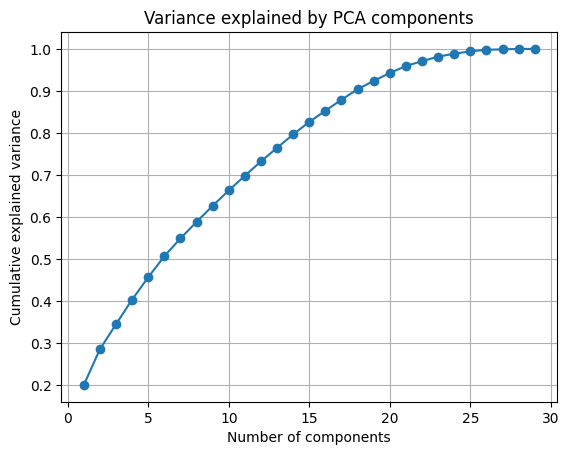

In [89]:
import numpy as np
import matplotlib.pyplot as plt

explained = np.cumsum(pca.explained_variance_ratio_)

plt.plot(np.arange(1, len(explained)+1), explained, marker='o')
plt.xlabel('Number of components')
plt.ylabel('Cumulative explained variance')
plt.title('Variance explained by PCA components')
plt.grid(True)
plt.show()

In [90]:
df_pca = pd.DataFrame(Z, columns=[f'PC{i+1}' for i in range(Z.shape[1])])
df_pca['mortality'] = y.values 
df_pca

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,...,PC21,PC22,PC23,PC24,PC25,PC26,PC27,PC28,PC29,mortality
0,-3.390821,2.272339,2.074303,-0.469702,0.538544,-1.511258,1.870421,1.937755,0.215955,1.003669,...,-0.197092,-0.395312,0.539791,-0.123979,-1.604926,-0.140249,0.257768,0.016530,1.054596e-15,0.0
1,-2.953899,2.249131,2.163599,-0.448915,0.626409,-1.592468,1.949035,1.924281,0.089462,0.854274,...,-0.670574,-0.587681,0.372234,-0.168335,-1.614717,-0.203875,0.258741,0.042954,1.720730e-15,0.0
2,-2.817368,2.359914,2.135918,-0.426392,0.604165,-1.727603,1.904268,1.937973,0.126576,0.938268,...,-1.063684,-0.482491,0.383665,0.011426,-1.554380,-0.185065,0.247506,0.078088,1.609708e-15,0.0
3,-2.798540,2.300266,2.131471,-0.455129,0.570473,-1.590925,1.902129,1.948615,0.220609,0.983723,...,-1.029939,-0.460671,0.470410,0.177570,-1.487614,-0.149486,0.243377,0.104814,1.498686e-15,0.0
4,-2.779712,2.240619,2.127023,-0.483865,0.536780,-1.454247,1.899989,1.959258,0.314642,1.029178,...,-0.996194,-0.438851,0.557154,0.343714,-1.420848,-0.113906,0.239248,0.131540,1.498686e-15,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1818558,4.256008,0.101990,-0.091704,1.445136,1.216714,0.692747,-1.860778,0.543907,-1.366920,0.457720,...,0.653695,0.549305,0.206813,-0.143952,-0.048155,0.647615,0.061677,0.160624,7.770407e-16,0.0
1818559,4.281088,0.041654,0.042105,1.309386,0.843453,1.169262,-1.915497,0.484571,-1.211572,0.446662,...,1.182590,0.576629,0.192648,-0.554394,-0.194457,0.599073,0.066221,0.133554,1.109069e-16,0.0
1818560,4.909724,0.105940,0.249669,1.204448,0.480933,1.422698,-1.937504,0.404371,-1.196151,0.321301,...,0.696663,0.682339,0.198154,-0.720516,-0.256703,0.527421,0.072040,0.110140,-2.221600e-16,0.0
1818561,4.720292,0.090192,0.196374,1.267695,0.688405,1.239149,-1.900663,0.427633,-1.290144,0.301242,...,0.763146,0.557139,0.081830,-1.110465,-0.402297,0.445708,0.047461,0.237881,1.109069e-16,0.0


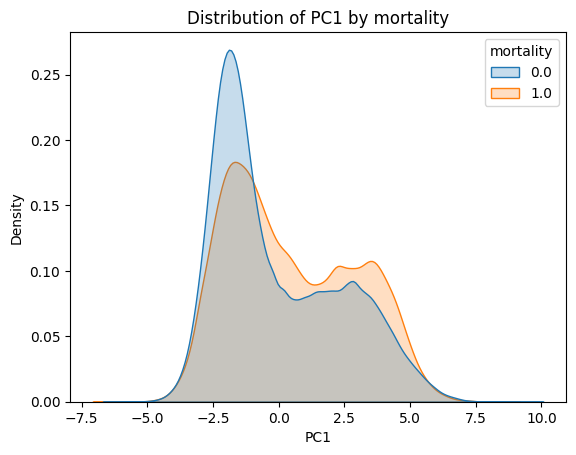

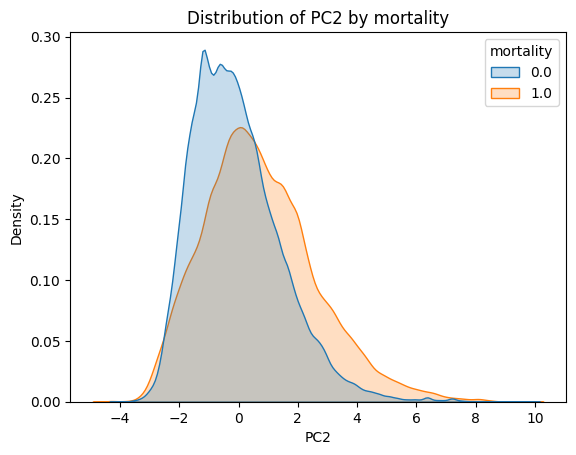

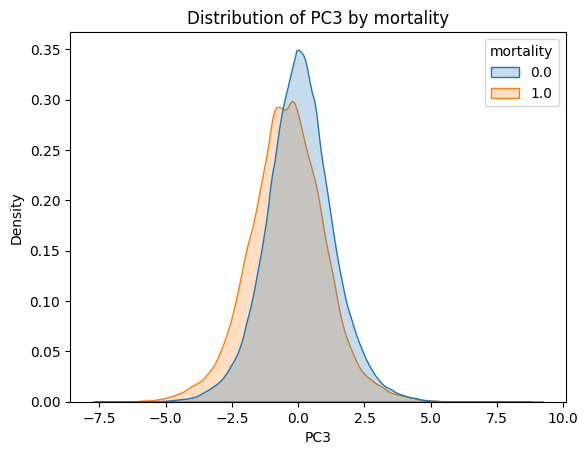

In [91]:
for i in range(3):  # first few components
    sns.kdeplot(data=df_pca, x=f'PC{i+1}', hue='mortality', fill=True, common_norm=False, )
    plt.title(f'Distribution of PC{i+1} by mortality')
    plt.show()

In [92]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score

X_pca = df_pca.drop(columns='mortality').values
y = df_pca['mortality'].values

logreg = LogisticRegression(max_iter=1000)
logreg.fit(X_pca, y)
y_pred = logreg.predict_proba(X_pca)[:, 1]

auc = roc_auc_score(y, y_pred)
print(f"AUC using all PCA components: {auc:.3f}")

auprc = average_precision_score(y, y_pred)
print(f"AUPRC: {auprc:.3f}")

AUC using all PCA components: 0.758
AUPRC: 0.278


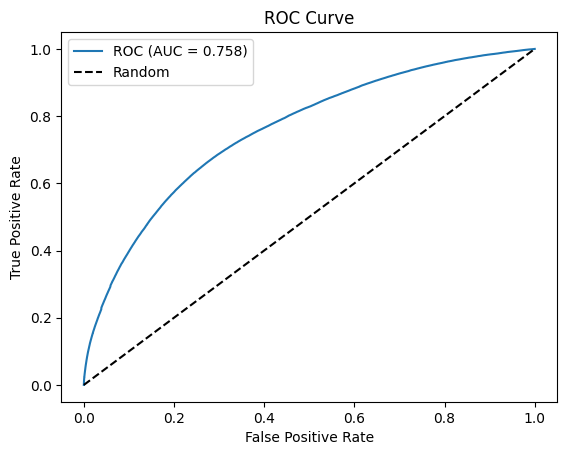

In [94]:
from sklearn.metrics import roc_curve, RocCurveDisplay
import matplotlib.pyplot as plt

fpr, tpr, _ = roc_curve(y, y_pred)
plt.plot(fpr, tpr, label=f"ROC (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], 'k--', label='Random')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

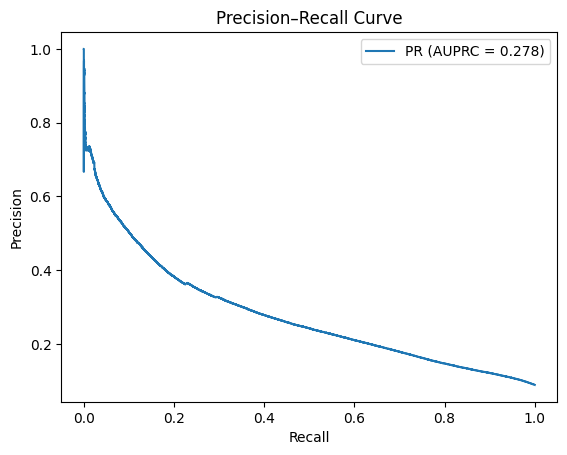

In [95]:
from sklearn.metrics import precision_recall_curve, PrecisionRecallDisplay

precision, recall, _ = precision_recall_curve(y, y_pred)
plt.plot(recall, precision, label=f"PR (AUPRC = {auprc:.3f})")
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision–Recall Curve')
plt.legend()
plt.show()

In [97]:
import numpy as np
from sklearn.metrics import roc_auc_score, average_precision_score
aucs = []
auprcs = []
for i in range(Z.shape[1]):
    auc = roc_auc_score(y, Z[:, i])   
    aucs.append(auc)

    auprc = average_precision_score(y, Z[:, i])
    auprcs.append(auprc)  

    print(f"PC{i+1}: AUC={auc:.3f}, AUPRC={auprc:.3f}")  

PC1: AUC=0.569, AUPRC=0.106
PC2: AUC=0.626, AUPRC=0.154
PC3: AUC=0.401, AUPRC=0.072
PC4: AUC=0.551, AUPRC=0.116
PC5: AUC=0.521, AUPRC=0.122
PC6: AUC=0.412, AUPRC=0.078
PC7: AUC=0.559, AUPRC=0.124
PC8: AUC=0.493, AUPRC=0.095
PC9: AUC=0.509, AUPRC=0.112
PC10: AUC=0.515, AUPRC=0.097
PC11: AUC=0.577, AUPRC=0.140
PC12: AUC=0.534, AUPRC=0.120
PC13: AUC=0.422, AUPRC=0.082
PC14: AUC=0.532, AUPRC=0.108
PC15: AUC=0.539, AUPRC=0.125
PC16: AUC=0.536, AUPRC=0.141
PC17: AUC=0.552, AUPRC=0.134
PC18: AUC=0.514, AUPRC=0.113
PC19: AUC=0.497, AUPRC=0.110
PC20: AUC=0.512, AUPRC=0.112
PC21: AUC=0.445, AUPRC=0.082
PC22: AUC=0.472, AUPRC=0.095
PC23: AUC=0.526, AUPRC=0.124
PC24: AUC=0.489, AUPRC=0.094
PC25: AUC=0.564, AUPRC=0.134
PC26: AUC=0.450, AUPRC=0.084
PC27: AUC=0.486, AUPRC=0.100
PC28: AUC=0.514, AUPRC=0.100
PC29: AUC=0.478, AUPRC=0.099


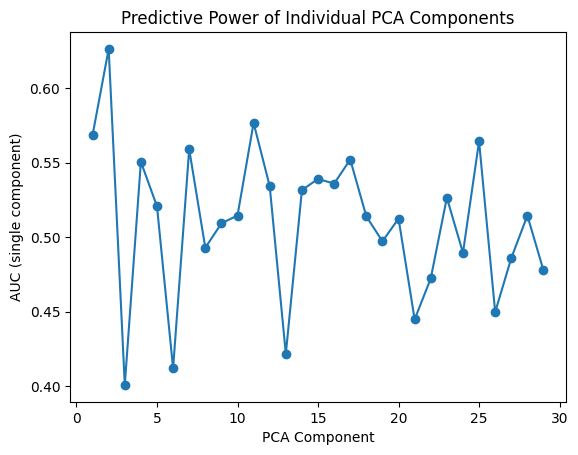

In [98]:
plt.plot(range(1, len(aucs)+1), aucs, marker='o')
plt.xlabel('PCA Component')
plt.ylabel('AUC (single component)')
plt.title('Predictive Power of Individual PCA Components')
plt.show()

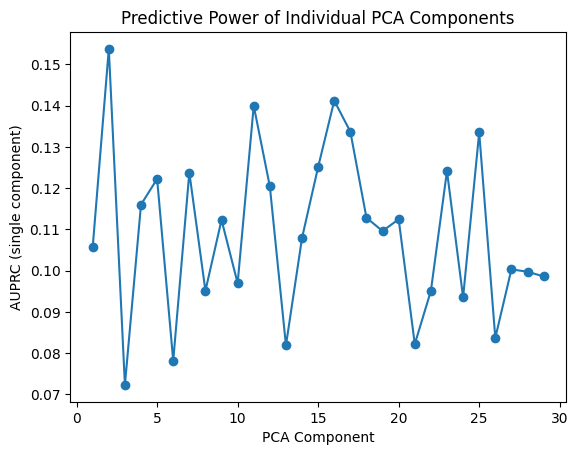

In [99]:
plt.plot(range(1, len(auprcs)+1), auprcs, marker='o')
plt.xlabel('PCA Component')
plt.ylabel('AUPRC (single component)')
plt.title('Predictive Power of Individual PCA Components')
plt.show()

In [103]:
loadings = pd.DataFrame(
    pca.components_.T,
    index=[f for f in X.columns if f not in ['mortality']],
    columns=[f'PC{i+1}' for i in range(pca.n_components_)]
)

top_pcs = range(1, X_scaled.shape[1])  # top 7 predictive components
for pc in top_pcs:
    print(f"\nTop features for PC{pc}:")
    print(loadings[f'PC{pc}'].sort_values(key=abs, ascending=False).head(10))

loadings[['PC2', 'PC11', 'PC16']].sort_values(by='PC2', ascending=False)


Top features for PC1:
age                         0.354220
blood_pressure_systolic     0.345650
weight_kg                   0.341733
blood_pressure_mean         0.320415
blood_pressure_diastolic    0.308976
heart_rate                 -0.308173
respiratory_rate           -0.287349
calcium                    -0.232810
potassium                  -0.196089
random_glucose              0.182712
Name: PC1, dtype: float64

Top features for PC2:
neutrophil_count          0.483538
white_blood_cell_count    0.422464
neutrophil_percent        0.403114
hematocrit                0.369239
hemoglobin                0.360011
creatinine                0.205293
random_glucose            0.184424
oxygen_saturation        -0.178981
potassium                -0.101448
calcium                  -0.098537
Name: PC2, dtype: float64

Top features for PC3:
hemoglobin                  0.490825
hematocrit                  0.489761
sodium                      0.316964
chloride                    0.290805
neutrophil_

,PC2,PC11,PC16
neutrophil_count,0.483538,-0.013141,0.061584
white_blood_cell_count,0.422464,0.009449,0.072239
neutrophil_percent,0.403114,-0.024423,-0.263395
hematocrit,0.369239,-0.043451,-0.039864
hemoglobin,0.360011,-0.040120,-0.025169
creatinine,0.205293,-0.161655,-0.117885
random_glucose,0.184424,0.019793,0.382982
crp,0.084503,-0.048640,0.532136
sodium,0.082606,0.085710,-0.033045
age,0.047066,-0.156620,0.053726


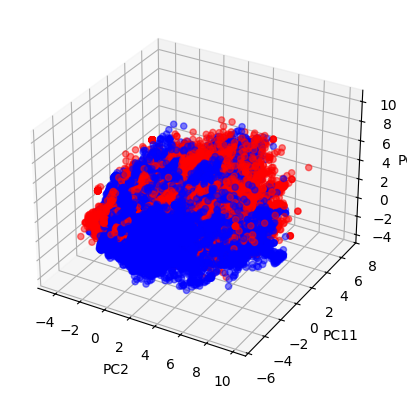

In [113]:
from mpl_toolkits.mplot3d import Axes3D

# Replace these with your actual PC2, PC11, PC16 arrays
x = df_pca['PC2']
y = df_pca['PC11']
z = df_pca['PC16']

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
colors = df_pca['mortality'].map({0: 'blue', 1: 'red'}) 

ax.scatter(x, y, z, c=colors, alpha=0.5)

ax.set_xlabel('PC2')
ax.set_ylabel('PC11')
ax.set_zlabel('PC16')
plt.show()

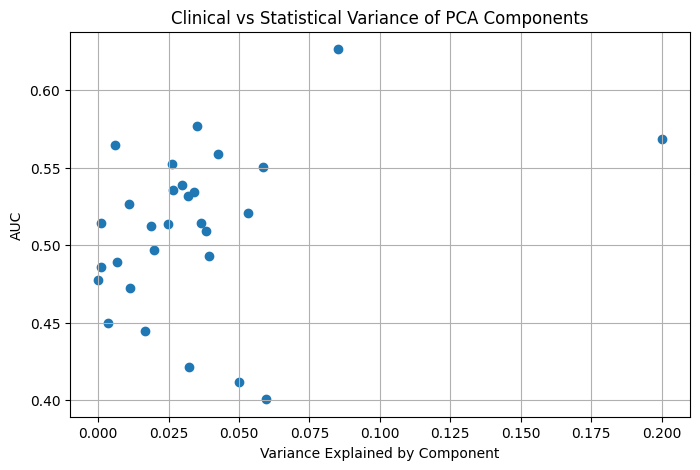

In [114]:
explained = pca.explained_variance_ratio_

plt.figure(figsize=(8,5))
plt.scatter(explained, aucs)
plt.xlabel('Variance Explained by Component')
plt.ylabel('AUC')
plt.title('Clinical vs Statistical Variance of PCA Components')
plt.grid(True)
plt.show()

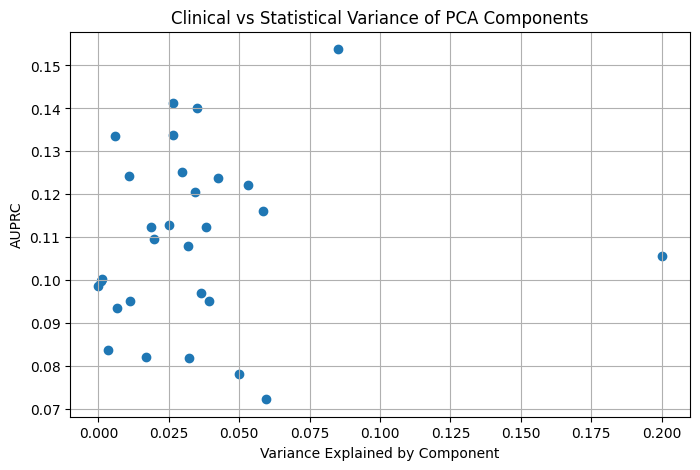

In [115]:
explained = pca.explained_variance_ratio_

plt.figure(figsize=(8,5))
plt.scatter(explained, auprcs)
plt.xlabel('Variance Explained by Component')
plt.ylabel('AUPRC')
plt.title('Clinical vs Statistical Variance of PCA Components')
plt.grid(True)
plt.show()

# All patients
## predicting sepsis and/or death

In [5]:
DATA_DIR = '/home/jake/Documents/AI_Clinician/choc_data'
FEATURES_DIR = os.path.join(DATA_DIR, 'features')
sepsis_df = pd.read_csv(os.path.join(FEATURES_DIR, 
                'ai_icu_primary_dx_sepsis', 'sepsis.csv.gz'), compression='gzip')
sepsis_encounters = sepsis_df['MASKED_ENCNTR_ID'].unique()

In [6]:
df_path = "/home/jake/Documents/AI_Clinician/choc_data/combined_data/hourly/combined_hourly_features_with_targets.parquet"
df = pd.read_parquet(df_path)

In [7]:
# create a new column 'sepsis' indicating if the encounter is in sepsis_encounters
df['sepsis'] = df['MASKED_ENCNTR_ID'].isin(sepsis_encounters).astype(int)
df['sepsis'].value_counts()

sepsis
0    17570856
1     4468032
Name: count, dtype: int64

In [8]:
# rename MASKED_ENCNTR_ID to encounter_id and EVENT_END_DT_TM to time
df = df.rename(columns={'MASKED_ENCNTR_ID': 'encounter_id', 'EVENT_END_DT_TM': 'time'})

In [9]:
df = df[['encounter_id', 'time'] + cols_to_keep + ['mortality', 'sepsis']]
df

,encounter_id,time,weight_kg,alt,calcium,chloride,creatinine,crp,hematocrit,hemoglobin,...,temperature,age,sex,white,black,hispanic,asian,other,mortality,sepsis
0,1163721634,2237-11-10 22:00:00,21.60,NaN,9.5,109.0,0.5,NaN,39.4,13.2,...,36.900000,5.38,0.0,1,0,0,0,0,0.0,0
1,1163721634,2237-11-10 23:00:00,21.60,NaN,9.5,109.0,0.5,NaN,39.4,13.2,...,36.900000,5.38,0.0,1,0,0,0,0,0.0,0
2,1163721634,2237-11-11 00:00:00,21.60,NaN,9.5,109.0,0.5,NaN,39.4,13.2,...,36.900000,5.38,0.0,1,0,0,0,0,0.0,0
3,1163721634,2237-11-11 01:00:00,21.60,NaN,9.5,109.0,0.5,NaN,39.4,13.2,...,36.900000,5.38,0.0,1,0,0,0,0,0.0,0
4,1163721634,2237-11-11 02:00:00,21.60,NaN,9.5,109.0,0.5,NaN,39.4,13.2,...,36.900000,5.38,0.0,1,0,0,0,0,0.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
22038883,1189452151,2254-11-04 21:00:00,3.06,18.0,10.1,104.0,0.4,NaN,51.4,16.4,...,36.766667,0.03,1.0,0,0,0,0,1,0.0,0
22038884,1189452151,2254-11-04 22:00:00,3.06,18.0,10.1,104.0,0.4,NaN,51.4,16.4,...,36.700000,0.03,1.0,0,0,0,0,1,0.0,0
22038885,1189452151,2254-11-04 23:00:00,3.06,18.0,10.1,104.0,0.4,NaN,51.4,16.4,...,36.866667,0.03,1.0,0,0,0,0,1,0.0,0
22038886,1189452151,2254-11-05 00:00:00,3.06,18.0,10.1,104.0,0.4,NaN,51.4,16.4,...,37.033333,0.03,1.0,0,0,0,0,1,0.0,0


In [10]:
# find encounter_ids with NaNs in any rows
nan_encounters = df[df.isna().any(axis=1)]['encounter_id'].unique()
nan_encounters.shape

(36644,)

In [11]:
n_encounters = df['encounter_id'].nunique()
n_encounters

49500

In [12]:
# drop the encounters with NaNs
df = df[~df['encounter_id'].isin(nan_encounters)]
df

,encounter_id,time,weight_kg,alt,calcium,chloride,creatinine,crp,hematocrit,hemoglobin,...,temperature,age,sex,white,black,hispanic,asian,other,mortality,sepsis
3041,1163732112,2237-11-07 22:00:00,2.9,30.000000,10.40,94.0,0.500000,0.02,33.300000,11.5,...,36.5,0.12,0.0,1,0,0,0,0,0.0,0
3042,1163732112,2237-11-07 23:00:00,2.9,29.666667,10.38,94.2,0.506667,0.02,33.253333,11.5,...,36.5,0.12,0.0,1,0,0,0,0,0.0,0
3043,1163732112,2237-11-08 00:00:00,2.9,29.333333,10.36,94.4,0.513333,0.02,33.206667,11.5,...,36.5,0.12,0.0,1,0,0,0,0,0.0,0
3044,1163732112,2237-11-08 01:00:00,2.9,29.000000,10.34,94.6,0.520000,0.02,33.160000,11.5,...,36.5,0.12,0.0,1,0,0,0,0,0.0,0
3045,1163732112,2237-11-08 02:00:00,2.9,28.666667,10.32,94.8,0.526667,0.02,33.113333,11.5,...,36.5,0.12,0.0,1,0,0,0,0,0.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
22038777,1189445073,2254-11-04 17:00:00,10.7,20.000000,9.40,103.0,0.300000,23.20,32.400000,11.1,...,36.6,3.82,0.0,1,0,0,0,0,0.0,0
22038778,1189445073,2254-11-04 18:00:00,10.7,20.000000,9.40,103.0,0.300000,23.20,32.400000,11.1,...,36.6,3.82,0.0,1,0,0,0,0,0.0,0
22038779,1189445073,2254-11-04 19:00:00,10.7,20.000000,9.40,103.0,0.300000,23.20,32.400000,11.1,...,36.6,3.82,0.0,1,0,0,0,0,0.0,0
22038780,1189445073,2254-11-04 20:00:00,10.7,20.000000,9.40,103.0,0.300000,23.20,32.400000,11.1,...,36.6,3.82,0.0,1,0,0,0,0,0.0,0


In [13]:
# get the mortality encounters
mortality_encounters = df[df['mortality'] == 1]['encounter_id'].unique()
len(mortality_encounters)

601

In [14]:
df['mortality'].value_counts()

mortality
0.0    8939702
1.0        601
Name: count, dtype: int64

In [15]:
# make all mortality encounters have mortality = 1
df.loc[df['encounter_id'].isin(mortality_encounters), 'mortality'] = 1
df['mortality'].value_counts()

mortality
0.0    8461639
1.0     478664
Name: count, dtype: int64

In [ ]:
# percent of mortality
print(f"Percent of mortality: {df['mortality'].mean() * 100:.2f}%")

In [16]:
df['sepsis'].value_counts()

sepsis
0    5679336
1    3260967
Name: count, dtype: int64

In [ ]:
# percent of sepsis encounters
print(f"Percent of sepsis encounters: {df['sepsis'].mean() * 100:.2f}%")

In [17]:
X = df[cols_to_keep]
y_mortality = df['mortality']
y_sepsis = df['sepsis']

In [18]:
# clear df from memory
del df, sepsis_df

In [19]:
X

,weight_kg,alt,calcium,chloride,creatinine,crp,hematocrit,hemoglobin,neutrophil_count,neutrophil_percent,...,oxygen_saturation,respiratory_rate,temperature,age,sex,white,black,hispanic,asian,other
3041,2.9,30.000000,10.40,94.0,0.500000,0.02,33.300000,11.5,1.258,15.0,...,100.0,34.000000,36.5,0.12,0.0,1,0,0,0,0
3042,2.9,29.666667,10.38,94.2,0.506667,0.02,33.253333,11.5,1.258,15.0,...,100.0,34.000000,36.5,0.12,0.0,1,0,0,0,0
3043,2.9,29.333333,10.36,94.4,0.513333,0.02,33.206667,11.5,1.258,15.0,...,100.0,34.000000,36.5,0.12,0.0,1,0,0,0,0
3044,2.9,29.000000,10.34,94.6,0.520000,0.02,33.160000,11.5,1.258,15.0,...,100.0,34.000000,36.5,0.12,0.0,1,0,0,0,0
3045,2.9,28.666667,10.32,94.8,0.526667,0.02,33.113333,11.5,1.258,15.0,...,100.0,34.000000,36.5,0.12,0.0,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
22038777,10.7,20.000000,9.40,103.0,0.300000,23.20,32.400000,11.1,1260.000,42.0,...,98.0,21.000000,36.6,3.82,0.0,1,0,0,0,0
22038778,10.7,20.000000,9.40,103.0,0.300000,23.20,32.400000,11.1,1260.000,42.0,...,98.0,21.333333,36.6,3.82,0.0,1,0,0,0,0
22038779,10.7,20.000000,9.40,103.0,0.300000,23.20,32.400000,11.1,1260.000,42.0,...,98.0,21.666667,36.6,3.82,0.0,1,0,0,0,0
22038780,10.7,20.000000,9.40,103.0,0.300000,23.20,32.400000,11.1,1260.000,42.0,...,98.0,22.000000,36.6,3.82,0.0,1,0,0,0,0


In [20]:
X_scaled = StandardScaler().fit_transform(X)
X_scaled.shape

(8940303, 29)

In [21]:
pca = PCA(n_components=None, svd_solver='randomized', random_state=0)  # randomized = faster
pca = pca.fit(X_scaled)
Z = pca.transform(X_scaled)

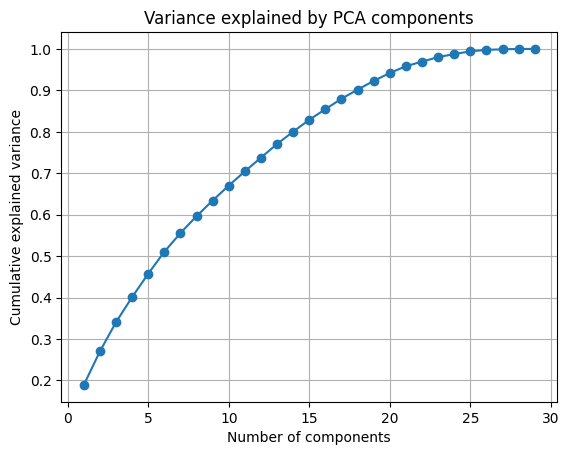

In [22]:
import numpy as np
import matplotlib.pyplot as plt

explained = np.cumsum(pca.explained_variance_ratio_)

plt.plot(np.arange(1, len(explained)+1), explained, marker='o')
plt.xlabel('Number of components')
plt.ylabel('Cumulative explained variance')
plt.title('Variance explained by PCA components')
plt.grid(True)
plt.show()

In [23]:
df_pca = pd.DataFrame(Z, columns=[f'PC{i+1}' for i in range(Z.shape[1])])
df_pca['mortality'] = y_mortality.values 
df_pca['sepsis'] = y_sepsis.values
df_pca

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,...,PC22,PC23,PC24,PC25,PC26,PC27,PC28,PC29,mortality,sepsis
0,-1.281216,-1.774504,-0.023573,0.479212,-0.952776,-1.744853,0.477363,0.178499,-0.009502,-0.265765,...,0.001621,0.008744,0.296271,0.139677,-0.021111,0.093910,-0.018906,2.956515e-16,0.0,0
1,-1.270608,-1.769750,-0.057805,0.506939,-0.967134,-1.680599,0.471836,0.167393,-0.001499,-0.264770,...,-0.003537,-0.036852,0.311672,0.146416,-0.024212,0.093814,-0.023260,5.176961e-16,0.0,0
2,-1.260001,-1.764996,-0.092037,0.534667,-0.981492,-1.616344,0.466309,0.156287,0.006504,-0.263775,...,-0.008695,-0.082448,0.327073,0.153156,-0.027313,0.093719,-0.027615,6.287184e-16,0.0,0
3,-1.249393,-1.760242,-0.126269,0.562394,-0.995850,-1.552090,0.460782,0.145181,0.014507,-0.262780,...,-0.013854,-0.128045,0.342474,0.159896,-0.030414,0.093623,-0.031969,8.507630e-16,0.0,0
4,-1.238785,-1.755488,-0.160501,0.590122,-1.010208,-1.487836,0.455255,0.134076,0.022510,-0.261785,...,-0.019012,-0.173641,0.357875,0.166636,-0.033515,0.093528,-0.036324,1.072808e-15,0.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8940298,1.511150,-1.495201,0.463049,1.405521,-2.537068,-0.775598,-2.141672,-0.221368,-0.066439,-0.119623,...,-0.949236,-0.143752,0.465253,-0.142791,-0.007788,0.020881,-0.004000,1.960986e-15,0.0,0
8940299,1.494054,-1.496873,0.463381,1.403897,-2.526877,-0.775130,-2.143534,-0.222599,-0.066782,-0.122007,...,-0.927730,-0.146210,0.461883,-0.140383,-0.007439,0.019900,-0.004307,1.960986e-15,0.0,0
8940300,1.476957,-1.498544,0.463712,1.402272,-2.516686,-0.774663,-2.145396,-0.223830,-0.067126,-0.124390,...,-0.906224,-0.148668,0.458512,-0.137975,-0.007090,0.018919,-0.004613,1.960986e-15,0.0,0
8940301,1.459861,-1.500215,0.464044,1.400648,-2.506495,-0.774196,-2.147258,-0.225060,-0.067470,-0.126774,...,-0.884718,-0.151126,0.455142,-0.135567,-0.006741,0.017937,-0.004920,1.960986e-15,0.0,0


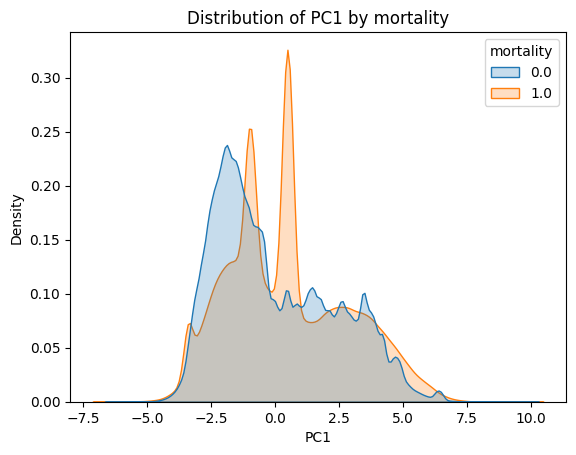

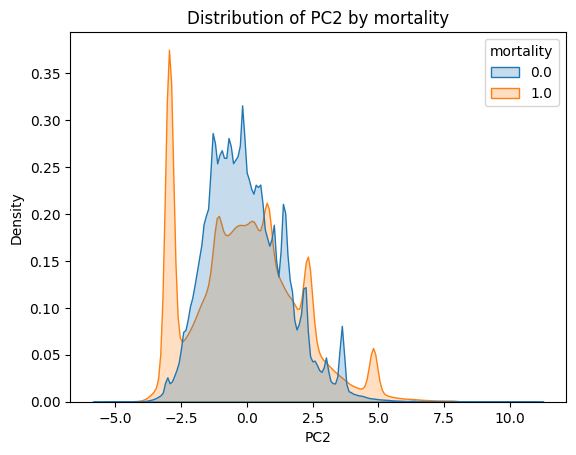

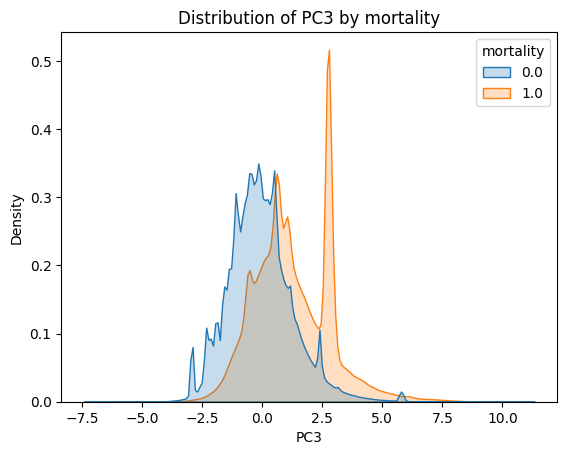

In [38]:
for i in range(3):  # first few components
    sns.kdeplot(data=df_pca, x=f'PC{i+1}', hue='mortality', fill=True, common_norm=False, )
    plt.title(f'Distribution of PC{i+1} by mortality')
    plt.show()

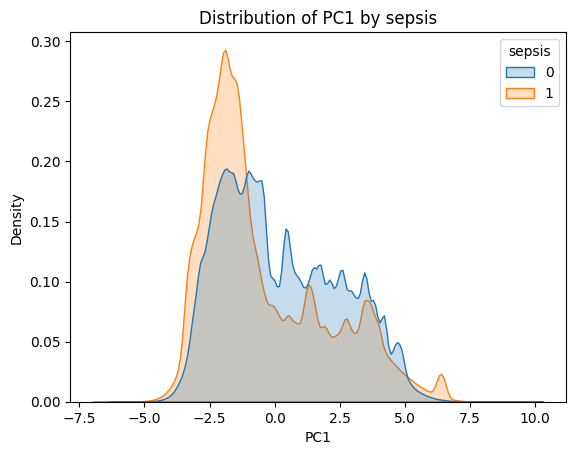

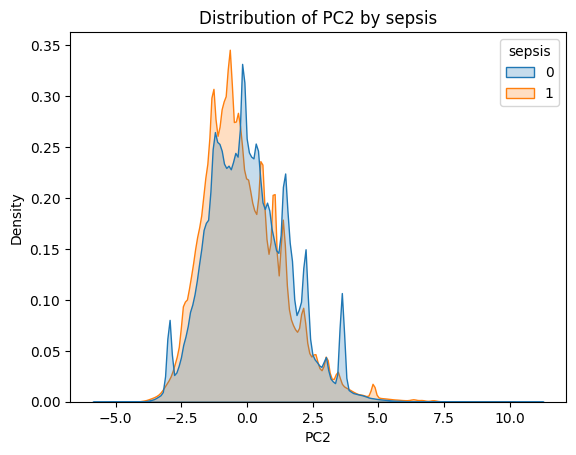

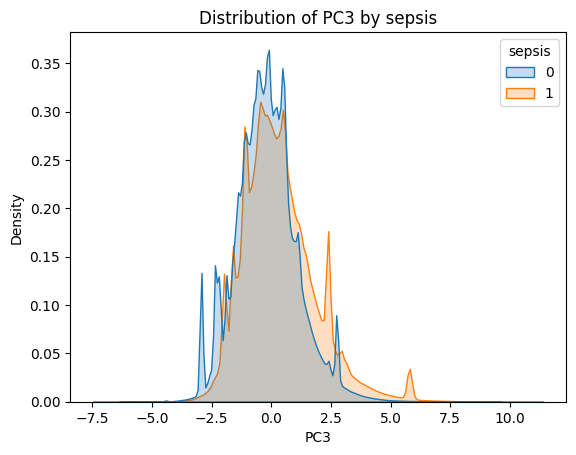

In [24]:
for i in range(3):  # first few components
    sns.kdeplot(data=df_pca, x=f'PC{i+1}', hue='sepsis', fill=True, common_norm=False, )
    plt.title(f'Distribution of PC{i+1} by sepsis')
    plt.show()


In [25]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score

X_pca = df_pca.drop(columns=['mortality', 'sepsis']).values
y_mortality = df_pca['mortality'].values

logreg = LogisticRegression(max_iter=1000)
logreg.fit(X_pca, y_mortality)
y_pred = logreg.predict_proba(X_pca)[:, 1]

auc = roc_auc_score(y_mortality, y_pred)
print(f"AUC using all PCA components: {auc:.3f}")

auprc = average_precision_score(y_mortality, y_pred)
print(f"AUPRC: {auprc:.3f}")

AUC using all PCA components: 0.820
AUPRC: 0.307


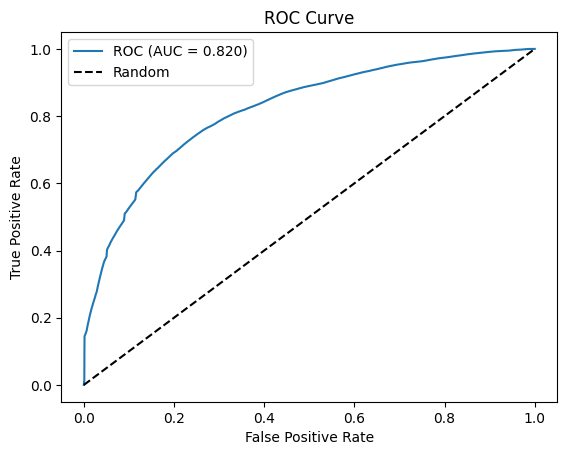

In [27]:
from sklearn.metrics import roc_curve, RocCurveDisplay
import matplotlib.pyplot as plt

fpr, tpr, _ = roc_curve(y_mortality, y_pred)
plt.plot(fpr, tpr, label=f"ROC (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], 'k--', label='Random')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

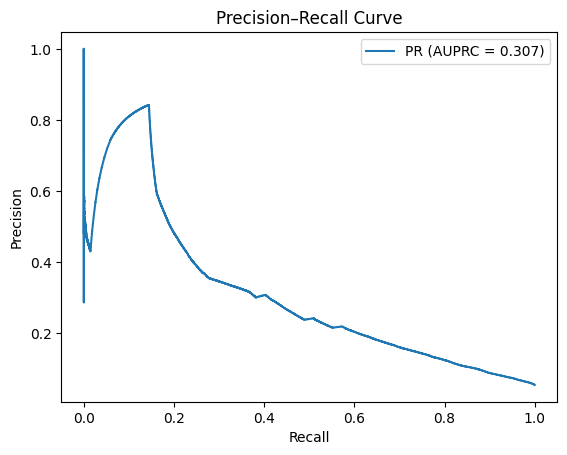

In [28]:
from sklearn.metrics import precision_recall_curve, PrecisionRecallDisplay

precision, recall, _ = precision_recall_curve(y_mortality, y_pred)
plt.plot(recall, precision, label=f"PR (AUPRC = {auprc:.3f})")
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision–Recall Curve')
plt.legend()
plt.show()

In [29]:
y_sepsis = df_pca['sepsis'].values

logreg = LogisticRegression(max_iter=1000)
logreg.fit(X_pca, y_sepsis)
y_pred = logreg.predict_proba(X_pca)[:, 1]

auc = roc_auc_score(y_sepsis, y_pred)
print(f"AUC using all PCA components: {auc:.3f}")

auprc = average_precision_score(y_sepsis, y_pred)
print(f"AUPRC: {auprc:.3f}")

AUC using all PCA components: 0.714
AUPRC: 0.570


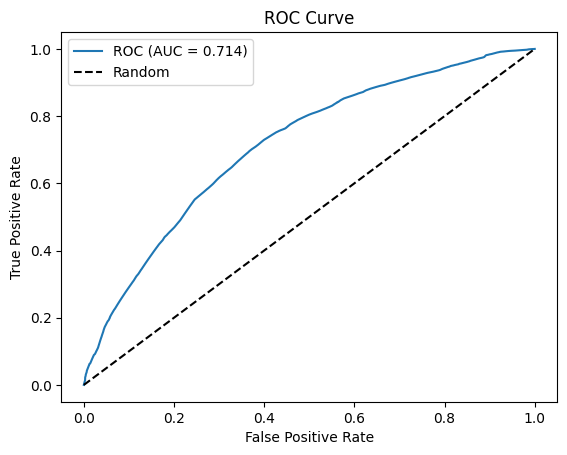

In [30]:
fpr, tpr, _ = roc_curve(y_sepsis, y_pred)
plt.plot(fpr, tpr, label=f"ROC (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], 'k--', label='Random')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

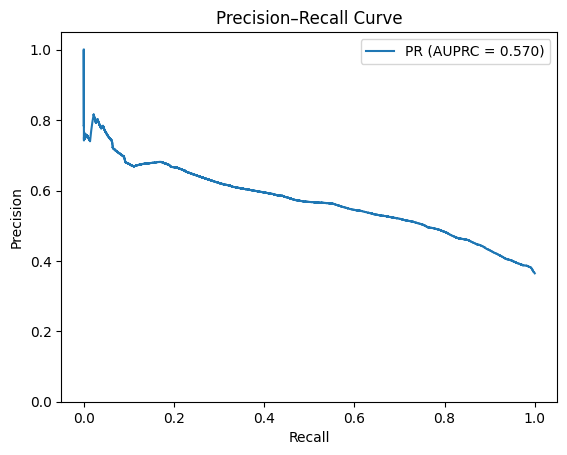

In [32]:
precision, recall, _ = precision_recall_curve(y_sepsis, y_pred)
plt.plot(recall, precision, label=f"PR (AUPRC = {auprc:.3f})")
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.ylim(0, 1.05)
plt.title('Precision–Recall Curve')
plt.legend()
plt.show()

In [33]:
aucs = []
auprcs = []
for i in range(Z.shape[1]):
    auc = roc_auc_score(y_mortality, Z[:, i])   
    aucs.append(auc)

    auprc = average_precision_score(y_mortality, Z[:, i])
    auprcs.append(auprc)  

    print(f"PC{i+1}: AUC={auc:.3f}, AUPRC={auprc:.3f}")  

PC1: AUC=0.564, AUPRC=0.065
PC2: AUC=0.486, AUPRC=0.068
PC3: AUC=0.747, AUPRC=0.157
PC4: AUC=0.526, AUPRC=0.150
PC5: AUC=0.440, AUPRC=0.057
PC6: AUC=0.508, AUPRC=0.077
PC7: AUC=0.474, AUPRC=0.076
PC8: AUC=0.584, AUPRC=0.083
PC9: AUC=0.510, AUPRC=0.091
PC10: AUC=0.366, AUPRC=0.044
PC11: AUC=0.591, AUPRC=0.083
PC12: AUC=0.613, AUPRC=0.090
PC13: AUC=0.487, AUPRC=0.053
PC14: AUC=0.557, AUPRC=0.073
PC15: AUC=0.556, AUPRC=0.073
PC16: AUC=0.586, AUPRC=0.110
PC17: AUC=0.488, AUPRC=0.071
PC18: AUC=0.544, AUPRC=0.071
PC19: AUC=0.478, AUPRC=0.064
PC20: AUC=0.491, AUPRC=0.089
PC21: AUC=0.487, AUPRC=0.055
PC22: AUC=0.558, AUPRC=0.064
PC23: AUC=0.468, AUPRC=0.069
PC24: AUC=0.537, AUPRC=0.079
PC25: AUC=0.520, AUPRC=0.062
PC26: AUC=0.515, AUPRC=0.061
PC27: AUC=0.477, AUPRC=0.054
PC28: AUC=0.486, AUPRC=0.059
PC29: AUC=0.417, AUPRC=0.076


In [34]:
aucs = []
auprcs = []
for i in range(Z.shape[1]):
    auc = roc_auc_score(y_sepsis, Z[:, i])   
    aucs.append(auc)

    auprc = average_precision_score(y_sepsis, Z[:, i])
    auprcs.append(auprc)  

    print(f"PC{i+1}: AUC={auc:.3f}, AUPRC={auprc:.3f}")  

PC1: AUC=0.409, AUPRC=0.335
PC2: AUC=0.449, AUPRC=0.338
PC3: AUC=0.593, AUPRC=0.470
PC4: AUC=0.476, AUPRC=0.336
PC5: AUC=0.549, AUPRC=0.395
PC6: AUC=0.568, AUPRC=0.425
PC7: AUC=0.488, AUPRC=0.367
PC8: AUC=0.473, AUPRC=0.362
PC9: AUC=0.479, AUPRC=0.365
PC10: AUC=0.475, AUPRC=0.357
PC11: AUC=0.549, AUPRC=0.419
PC12: AUC=0.451, AUPRC=0.338
PC13: AUC=0.534, AUPRC=0.424
PC14: AUC=0.525, AUPRC=0.401
PC15: AUC=0.542, AUPRC=0.404
PC16: AUC=0.499, AUPRC=0.373
PC17: AUC=0.503, AUPRC=0.374
PC18: AUC=0.441, AUPRC=0.340
PC19: AUC=0.500, AUPRC=0.365
PC20: AUC=0.497, AUPRC=0.362
PC21: AUC=0.540, AUPRC=0.399
PC22: AUC=0.542, AUPRC=0.404
PC23: AUC=0.466, AUPRC=0.351
PC24: AUC=0.548, AUPRC=0.394
PC25: AUC=0.469, AUPRC=0.353
PC26: AUC=0.519, AUPRC=0.365
PC27: AUC=0.497, AUPRC=0.353
PC28: AUC=0.488, AUPRC=0.351
PC29: AUC=0.438, AUPRC=0.325


In [36]:
loadings = pd.DataFrame(
    pca.components_.T,
    index=[f for f in X.columns if f not in ['mortality']],
    columns=[f'PC{i+1}' for i in range(pca.n_components_)]
)

top_pcs = range(1, X_scaled.shape[1])  # top 7 predictive components
for pc in top_pcs:
    print(f"\nTop features for PC{pc}:")
    print(loadings[f'PC{pc}'].sort_values(key=abs, ascending=False).head(10))

loadings[['PC2', 'PC11', 'PC16']].sort_values(by='PC2', ascending=False)


Top features for PC1:
age                         0.361282
weight_kg                   0.353567
blood_pressure_systolic     0.348746
heart_rate                 -0.321480
blood_pressure_diastolic    0.318103
blood_pressure_mean         0.314805
respiratory_rate           -0.302992
calcium                    -0.226485
potassium                  -0.183453
random_glucose              0.179907
Name: PC1, dtype: float64

Top features for PC2:
hematocrit                0.500970
hemoglobin                0.493330
neutrophil_count          0.389951
neutrophil_percent        0.345876
white_blood_cell_count    0.340679
creatinine                0.169672
oxygen_saturation        -0.163673
sodium                    0.119260
other                     0.106329
white                    -0.087114
Name: PC2, dtype: float64

Top features for PC3:
neutrophil_count            0.346977
hematocrit                 -0.308962
hemoglobin                 -0.305532
white_blood_cell_count      0.301772
chloride   

,PC2,PC11,PC16
hematocrit,0.500970,0.046192,-0.101371
hemoglobin,0.493330,0.043707,-0.095824
neutrophil_count,0.389951,-0.137141,0.055086
neutrophil_percent,0.345876,-0.081544,-0.114985
white_blood_cell_count,0.340679,-0.127173,0.072496
creatinine,0.169672,-0.007042,-0.083365
sodium,0.119260,0.207304,0.138434
other,0.106329,0.002897,0.001559
capillary_refill,0.085848,0.215106,0.471024
age,0.076381,-0.165625,0.077646


# Autoencoder as a "non-linear PCA"

In [9]:
df_path = "/home/jake/Documents/AI_Clinician/choc_data/combined_data/hourly/combined_hourly_features_phoenix_sepsis_prop_0.8.parquet"
df = pd.read_parquet(df_path)
df

,encounter_id,time,airway_type,breath_sequence,control_variable,expiratory_pressure,fio2,mean_airway_pressure,mode_of_ventilation,nitric_oxide,...,temperature,vis,age,mortality,sex,white,black,hispanic,asian,other
0,1165711196,2239-11-13 13:00:00,0.0,0.0,0.0,0.0,0.21,0.0,0.0,0.0,...,36.800,0.0,0.00,0.0,1.0,0,0,0,1,0
1,1165711196,2239-11-13 14:00:00,0.0,0.0,0.0,0.0,0.21,0.0,0.0,0.0,...,36.875,0.0,0.00,0.0,1.0,0,0,0,1,0
2,1165711196,2239-11-13 15:00:00,0.0,0.0,0.0,0.0,0.21,0.0,0.0,0.0,...,36.950,0.0,0.00,0.0,1.0,0,0,0,1,0
3,1165711196,2239-11-13 16:00:00,0.0,0.0,0.0,0.0,0.21,0.0,0.0,0.0,...,37.025,0.0,0.00,0.0,1.0,0,0,0,1,0
4,1165711196,2239-11-13 17:00:00,0.0,0.0,0.0,0.0,0.21,0.0,0.0,0.0,...,37.100,0.0,0.00,0.0,1.0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1818558,1189429156,2254-11-02 19:00:00,2.0,0.0,0.0,0.0,0.21,0.0,0.0,0.0,...,37.150,0.0,232.44,0.0,1.0,1,0,0,0,0
1818559,1189429156,2254-11-02 20:00:00,2.0,0.0,0.0,0.0,0.21,0.0,0.0,0.0,...,37.100,0.0,232.44,0.0,1.0,1,0,0,0,0
1818560,1189429156,2254-11-02 21:00:00,2.0,0.0,0.0,0.0,0.21,0.0,0.0,0.0,...,37.100,0.0,232.44,0.0,1.0,1,0,0,0,0
1818561,1189429156,2254-11-02 22:00:00,2.0,0.0,0.0,0.0,0.21,0.0,0.0,0.0,...,37.100,0.0,232.44,0.0,1.0,1,0,0,0,0


In [10]:
cols_to_keep = ['weight_kg', 'alt', 'calcium',
       'chloride', 'creatinine', 'crp', 'hematocrit', 'hemoglobin',
       'neutrophil_count', 'neutrophil_percent', 'potassium', 'random_glucose',
       'sodium', 'white_blood_cell_count',
       'blood_pressure_diastolic', 'blood_pressure_mean',
       'blood_pressure_systolic', 'capillary_refill', 'heart_rate',
       'oxygen_saturation', 'respiratory_rate', 'temperature', 'age',
       'sex', 'white', 'black', 'hispanic', 'asian', 'other']

In [11]:
# get the mortality encounters
mortality_encounters = df[df['mortality'] == 1]['encounter_id'].unique()
# make all mortality encounters have mortality = 1
df.loc[df['encounter_id'].isin(mortality_encounters), 'mortality'] = 1
df['mortality'].value_counts()

# separate features and labels
X = df[cols_to_keep]
y = df['mortality'].values

In [12]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [19]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

# Convert to torch tensors
X_tensor = torch.tensor(X_scaled, dtype=torch.float32)
dataset = TensorDataset(X_tensor)
loader = DataLoader(dataset, batch_size=2048, shuffle=True)

# Define the autoencoder architecture
class Autoencoder(nn.Module):
    def __init__(self, input_dim, latent_dim=4):
        super(Autoencoder, self).__init__()
        # Encoder
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, latent_dim)  # Bottleneck
        )
        # Decoder
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 32),
            nn.ReLU(),
            nn.Linear(32, 64),
            nn.ReLU(),
            nn.Linear(64, input_dim),
        )

    def forward(self, x):
        z = self.encoder(x)
        x_hat = self.decoder(z)
        return x_hat, z


# try different latent dimensions
latent_dims = [1, 2, 3, 4, 8, 16]

# create storage for losses which we will plot after
losses = {}

for latent_dim in latent_dims:
    losses[latent_dim] = []
    print(f"\nTraining autoencoder with latent dimension: {latent_dim}")
    # Initialize
    input_dim = X_scaled.shape[1]
    model = Autoencoder(input_dim, latent_dim)
    optimizer = optim.Adam(model.parameters(), lr=1e-3)
    criterion = nn.MSELoss()

    # Training loop
    n_epochs = 25
    for epoch in range(n_epochs):
        print(f"Epoch {epoch+1}/{n_epochs}")
        batch_num = 0
        for batch in loader:
            batch_num += 1
            if batch_num % 100 == 0:
                print(f"  Batch {batch_num}")
            x_batch = batch[0]
            optimizer.zero_grad()
            x_hat, _ = model(x_batch)
            loss = criterion(x_hat, x_batch)
            losses[latent_dim].append(loss.item())
            loss.backward()
            optimizer.step()
        if (epoch+1) % 1 == 0:
            print(f"Epoch {epoch+1}/{n_epochs}, Loss={loss.item():.4f}")

    # Extract latent features (the "health scores")
    with torch.no_grad():
        _, latent = model(X_tensor)
    latent_np = latent.numpy()


Training autoencoder with latent dimension: 1
Epoch 1/25
  Batch 100
  Batch 200
  Batch 300
  Batch 400
  Batch 500
  Batch 600
  Batch 700
  Batch 800
Epoch 1/25, Loss=0.7203
Epoch 2/25
  Batch 100
  Batch 200
  Batch 300
  Batch 400
  Batch 500
  Batch 600
  Batch 700
  Batch 800
Epoch 2/25, Loss=0.6835
Epoch 3/25
  Batch 100
  Batch 200
  Batch 300
  Batch 400
  Batch 500
  Batch 600
  Batch 700
  Batch 800
Epoch 3/25, Loss=0.6132
Epoch 4/25
  Batch 100
  Batch 200
  Batch 300
  Batch 400
  Batch 500
  Batch 600
  Batch 700
  Batch 800
Epoch 4/25, Loss=0.5990
Epoch 5/25
  Batch 100
  Batch 200
  Batch 300
  Batch 400
  Batch 500
  Batch 600
  Batch 700
  Batch 800
Epoch 5/25, Loss=0.5583
Epoch 6/25
  Batch 100
  Batch 200
  Batch 300
  Batch 400
  Batch 500
  Batch 600
  Batch 700
  Batch 800
Epoch 6/25, Loss=0.5924
Epoch 7/25
  Batch 100
  Batch 200
  Batch 300
  Batch 400
  Batch 500
  Batch 600
  Batch 700
  Batch 800
Epoch 7/25, Loss=0.5796
Epoch 8/25
  Batch 100
  Batch 200
 

In [23]:
losses[16]

[0.992281973361969,
 1.0090473890304565,
 1.0274817943572998,
 0.9945988059043884,
 0.9611613154411316,
 1.016265630722046,
 0.9892985820770264,
 0.988994836807251,
 0.9993667006492615,
 1.0126380920410156,
 1.0139273405075073,
 1.007582187652588,
 0.9952806830406189,
 0.9810330867767334,
 0.9739491939544678,
 1.0071390867233276,
 0.9728172421455383,
 0.9828833341598511,
 0.9643903374671936,
 0.9701628684997559,
 0.952009916305542,
 0.9732506275177002,
 0.9522802233695984,
 0.9275577068328857,
 0.9563778638839722,
 0.9292532801628113,
 0.9040197134017944,
 0.9379100203514099,
 0.9468144178390503,
 0.9252207279205322,
 0.8877564668655396,
 0.8842761516571045,
 0.8866628408432007,
 0.849519670009613,
 0.8665212392807007,
 0.8526003360748291,
 0.8426954746246338,
 0.8640226125717163,
 0.8163834810256958,
 0.8355662226676941,
 0.7869055271148682,
 0.8091515898704529,
 0.7950510382652283,
 0.8013131618499756,
 0.8052428960800171,
 0.7812991142272949,
 0.7725653052330017,
 0.7605298757553101

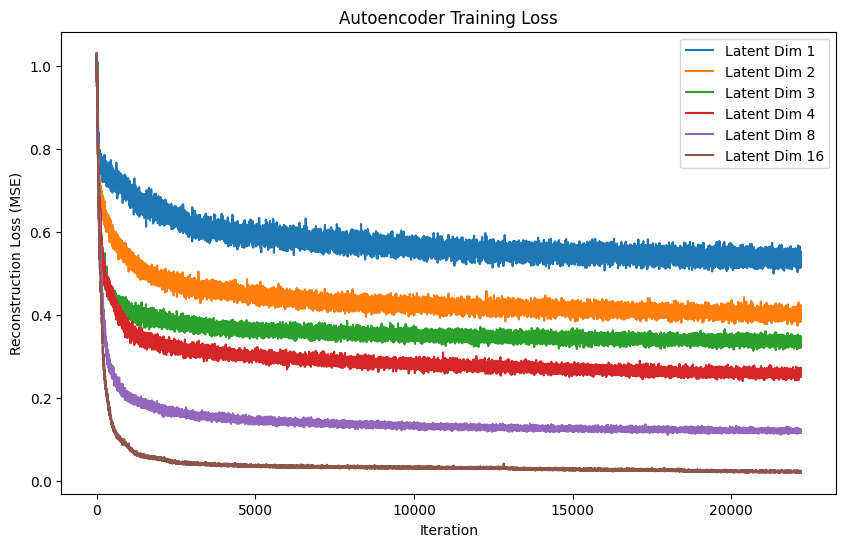

In [20]:
# plot losses for each latent dimension
plt.figure(figsize=(10, 6))
for latent_dim, loss_values in losses.items():
    plt.plot(loss_values, label=f'Latent Dim {latent_dim}')
plt.xlabel('Iteration')
plt.ylabel('Reconstruction Loss (MSE)')
plt.title('Autoencoder Training Loss')
plt.legend()
plt.show()

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim

class VAE(nn.Module):
    def __init__(self, input_dim, latent_dim=2):
        super(VAE, self).__init__()
        # Encoder
        self.fc1 = nn.Linear(input_dim, 64)
        self.fc2_mu = nn.Linear(64, latent_dim)
        self.fc2_logvar = nn.Linear(64, latent_dim)
        # Decoder
        self.fc3 = nn.Linear(latent_dim, 64)
        self.fc4 = nn.Linear(64, input_dim)
        self.relu = nn.ReLU()

    def encode(self, x):
        h = self.relu(self.fc1(x))
        mu = self.fc2_mu(h)
        logvar = self.fc2_logvar(h)
        return mu, logvar

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z):
        h = self.relu(self.fc3(z))
        return self.fc4(h)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        x_hat = self.decode(z)
        return x_hat, mu, logvar

def vae_loss(x_hat, x, mu, logvar):
    recon_loss = nn.functional.mse_loss(x_hat, x, reduction='sum')
    kl_loss = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    return recon_loss + kl_loss

# Example usage
input_dim = X_scaled.shape[1]
latent_dim = 2
vae = VAE(input_dim, latent_dim)
optimizer = optim.Adam(vae.parameters(), lr=1e-3)

X_tensor = torch.tensor(X_scaled, dtype=torch.float32)
for epoch in range(50):
    optimizer.zero_grad()
    x_hat, mu, logvar = vae(X_tensor)
    loss = vae_loss(x_hat, X_tensor, mu, logvar)
    loss.backward()
    optimizer.step()
    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch+1}, Loss={loss.item():.2f}")
